# Scenario 2: Website Analytics Debug

**Goal:** the marketing team's engagement code shows impossible results (bounce rates of 100%+, negative session times). Debug it, add validation, fix time calculations, and visualize.

**Approach:** I reproduced the bug on test data first, then compared a vague *"fix this"* prompt with a detailed prompt that explained the data and the symptoms.

## Test data
Page-level web logs: **one row per page view**, with a timestamp. I added realistic problems: duplicate log rows, timestamps that arrive out of order, negative `duration` values from clock sync issues, a bot session that lasts days, and numbers stored as text.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
rows = []
for s in range(300):
    device = rng.choice(['desktop', 'mobile', 'tablet'], p=[0.45, 0.45, 0.10])
    n_pages = 1 if rng.random() < 0.4 else int(rng.integers(2, 9))
    t = pd.Timestamp('2026-11-01') + pd.Timedelta(minutes=int(rng.integers(0, 60*24*14)))
    for p in range(n_pages):
        dur = float(rng.exponential(45))
        rows.append({'session_id': f'S{s:04d}', 'timestamp': t, 'page_views': 1,
                     'duration': dur, 'device_type': device})
        t += pd.Timedelta(seconds=dur)
logs_df = pd.DataFrame(rows)

# Real-world problems
logs_df.loc[rng.choice(len(logs_df), 15, replace=False), 'duration'] *= -1          # clock-sync glitches
logs_df = pd.concat([logs_df, logs_df.sample(20, random_state=1)])                     # duplicate log rows
logs_df = logs_df.sample(frac=1, random_state=2).reset_index(drop=True)                # out-of-order arrival
bot = pd.DataFrame({'session_id': 'BOT1', 'timestamp': pd.date_range('2026-11-02', periods=3, freq='2D'),
                    'page_views': 1, 'duration': 86400.0, 'device_type': 'desktop'})
logs_df = pd.concat([logs_df, bot], ignore_index=True)
logs_df['duration'] = logs_df['duration'].round(1).astype(str)                         # numbers stored as text
logs_df.loc[0, 'duration'] = 'n/a'

print(logs_df.shape)
logs_df.head()

(1015, 5)


,session_id,timestamp,page_views,duration,device_type
0,S0157,2026-11-01 04:43:08.915479395,1,n/a,desktop
1,S0065,2026-11-01 13:37:14.996241531,1,15.4,mobile
2,S0221,2026-11-14 05:11:28.641089020,1,62.6,tablet
3,S0273,2026-11-03 06:22:00.000000000,1,22.7,desktop
4,S0117,2026-11-13 08:34:53.245938942,1,19.5,desktop


## Reproducing the bug with the original code

In [2]:
def analyze_user_engagement(logs_df):
    metrics = {
        'bounce_rate': logs_df.groupby('session_id')['page_views'].apply(
            lambda x: x == 1).mean(),
        'avg_session_time': logs_df.groupby('session_id')['duration'].sum(),
        'pages_per_session': logs_df.groupby('session_id')['page_views'].mean()
    }

    device_metrics = logs_df.groupby('device_type').agg({
        'session_id': 'count',
        'duration': 'mean',
        'page_views': 'sum'
    })

    return metrics, device_metrics

test = logs_df.copy()
test['duration'] = pd.to_numeric(test['duration'], errors='coerce')   # otherwise it can't even run
orig_metrics, orig_device = analyze_user_engagement(test)
print("Bounce rate:", orig_metrics['bounce_rate'])
print("Pages per session (every session):", orig_metrics['pages_per_session'].unique())
print("avg_session_time is a", type(orig_metrics['avg_session_time']).__name__,
      "with", len(orig_metrics['avg_session_time']), "values, not one average")
print("Negative session times:", (orig_metrics['avg_session_time'] < 0).sum())

Bounce rate: 1.0
Pages per session (every session): [1.]
avg_session_time is a Series with 301 values, not one average
Negative session times: 3


**Confirmed:** bounce rate is **100%** and pages per session is **1.0**, which is impossible since many sessions have several pages. Some session times are **negative**, and `avg_session_time` isn't an average at all.

---
## Attempt 1: Vague prompt

### Your Prompt:
> *This code gives wrong bounce rates and negative session times. Fix it.* (followed by the code)

**Why I wrote it this way:** a quick *"fix this"* request is the most common way people use AI for debugging. I wanted to see whether the AI could find the root causes without being told what the data looks like.

### Generated Code:

In [3]:
# ---- AI-generated code (vague prompt) ----
def analyze_user_engagement_fixed(logs_df):
    logs_df = logs_df[logs_df['duration'] >= 0]          # remove negative durations

    session_pages = logs_df.groupby('session_id')['page_views'].sum()
    metrics = {
        'bounce_rate': (session_pages == 1).mean(),
        'avg_session_time': logs_df.groupby('session_id')['duration'].sum().mean(),
        'pages_per_session': session_pages.mean()
    }
    device_metrics = logs_df.groupby('device_type').agg({
        'session_id': 'nunique', 'duration': 'mean', 'page_views': 'sum'})
    return metrics, device_metrics

### Testing the vague-prompt code

In [4]:
try:
    m, d = analyze_user_engagement_fixed(logs_df.copy())
    print(m)
except Exception as e:
    print("FAILED on raw data:", type(e).__name__, "-", e)

m, d = analyze_user_engagement_fixed(test.copy())   # after I manually converted duration to numbers
print("After manual cleanup:", {k: round(v, 3) for k, v in m.items()})

FAILED on raw data: TypeError - '>=' not supported between instances of 'str' and 'int'
After manual cleanup: {'bounce_rate': np.float64(0.4), 'avg_session_time': np.float64(1010.755), 'pages_per_session': np.float64(3.327)}


**What it got right:** it found the main **aggregation bug**. Bounce rate now aggregates to the session level first (pages summed per session, then the share of sessions with exactly 1 page). It also correctly switched `count` to `nunique` for sessions.

**What it missed:**
- It **crashed on the raw data** (comparing text to a number) because it never checked data types.
- It **drops negative rows** instead of fixing the time calculation, so it hides the symptom rather than the cause.
- **Duplicates are still counted**, inflating pages and time.
- The 3-day **bot session** still drags up the average session time.
- No visualizations.

---
## Attempt 2: Detailed debugging prompt

### Your Prompt:
> *You are a senior analytics engineer. Debug this pandas function. Context:*
> *- `logs_df` has ONE ROW PER PAGE VIEW: `session_id`, `timestamp`, `page_views` (always 1), `duration` (seconds on that page; sometimes negative from client clock errors; sometimes stored as text), `device_type`.*
> *- Logs can contain duplicate rows and arrive out of order.*
> *- Symptoms: bounce rate shows 100%+, some session times are negative.*
>
> *Please: (1) explain each bug and why it causes the symptom, (2) aggregate to the session level before computing metrics, (3) compute session duration from timestamps (last − first) instead of summing per-page durations, (4) add a validation step that returns a report of what was removed or fixed (types, duplicates, negative values, sessions longer than 4 hours as likely bots), (5) add assertions that the final metrics are in valid ranges, (6) create summary charts for the marketing team.*

**Why I wrote it this way:** I explained the **grain of the data** (one row per page view), which is the key to the bug. I also listed the **data-quality issues I knew about**, and asked the AI to **explain** the bugs, not just patch them, so I could check its reasoning.

### Generated Code:

**AI's explanation of the bugs:**
1. **Bounce rate:** `.apply(lambda x: x == 1)` returns a True/False value for every *row*. Since every row has `page_views == 1`, the mean is always 100%. Bounce rate must be calculated per *session*: the share of sessions with exactly 1 page view.
2. **Pages per session:** `.mean()` of a column that's always 1 is always 1. It should be `sum` per session, then the average across sessions.
3. **avg_session_time:** `.sum()` per session returns a whole Series, not an average. Summing client-reported durations also carries the negative glitches into the total. Session length should come from server timestamps: last − first.
4. **device_metrics:** `count` counts page-view rows, not sessions, and `duration: mean` averages pages, not sessions.

In [5]:
# ---- AI-generated code (detailed prompt) ----
MAX_SESSION = pd.Timedelta(hours=4)

def validate_logs(df):
    """Clean page-level logs and return (clean_df, report)."""
    report = {'rows_in': len(df)}
    df = df.copy()

    required = {'session_id', 'timestamp', 'page_views', 'duration', 'device_type'}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    # Types
    df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce', utc=True)
    df['duration'] = pd.to_numeric(df['duration'], errors='coerce')
    df['page_views'] = pd.to_numeric(df['page_views'], errors='coerce')
    report['bad_timestamps'] = int(df['timestamp'].isna().sum())
    report['non_numeric_durations'] = int(df['duration'].isna().sum())
    df = df.dropna(subset=['session_id', 'timestamp'])

    # Duplicates
    dupes = df.duplicated(subset=['session_id', 'timestamp', 'duration'])
    report['duplicate_rows_removed'] = int(dupes.sum())
    df = df[~dupes]

    # Negative per-page durations: keep the page view, but blank the bad duration
    neg = df['duration'] < 0
    report['negative_durations_nulled'] = int(neg.sum())
    df.loc[neg, 'duration'] = np.nan

    # Order events within each session
    df = df.sort_values(['session_id', 'timestamp'])
    report['rows_out'] = len(df)
    return df, report


def analyze_user_engagement_v2(logs_df):
    clean, report = validate_logs(logs_df)

    sessions = clean.groupby('session_id').agg(
        device_type=('device_type', 'first'),
        pages=('page_views', 'sum'),
        start=('timestamp', 'min'),
        end=('timestamp', 'max'),
        last_page_seconds=('duration', 'last'),
    )
    # Session length = time between first and last page + time spent on the last page
    sessions['session_seconds'] = ((sessions['end'] - sessions['start']).dt.total_seconds()
                                   + sessions['last_page_seconds'].fillna(0))

    # Remove likely bots / abandoned tabs
    too_long = sessions['session_seconds'] > MAX_SESSION.total_seconds()
    report['sessions_over_4h_removed'] = sessions.index[too_long].tolist()
    sessions = sessions[~too_long]

    metrics = {
        'sessions': len(sessions),
        'bounce_rate': (sessions['pages'] == 1).mean(),
        'avg_session_minutes': sessions['session_seconds'].mean() / 60,
        'median_session_minutes': sessions['session_seconds'].median() / 60,
        'pages_per_session': sessions['pages'].mean(),
    }

    # Sanity checks: catch impossible results before they reach a dashboard
    assert 0 <= metrics['bounce_rate'] <= 1, "Bounce rate out of range"
    assert (sessions['session_seconds'] >= 0).all(), "Negative session time"
    assert metrics['pages_per_session'] >= 1, "Pages per session below 1"

    device_metrics = sessions.groupby('device_type').agg(
        sessions=('pages', 'size'),
        bounce_rate=('pages', lambda p: (p == 1).mean()),
        avg_session_minutes=('session_seconds', lambda s: s.mean() / 60),
        pages_per_session=('pages', 'mean'),
    ).round(3)

    return metrics, device_metrics, sessions, report


def plot_engagement(sessions, device_metrics):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    (device_metrics['bounce_rate'] * 100).plot(kind='bar', ax=axes[0], color='coral')
    axes[0].set_title('Bounce Rate by Device (%)'); axes[0].set_ylabel('%'); axes[0].tick_params(axis='x', rotation=0)

    axes[1].hist(sessions['session_seconds'] / 60, bins=30, color='steelblue')
    axes[1].set_title('Session Length Distribution'); axes[1].set_xlabel('Minutes'); axes[1].set_ylabel('Sessions')

    sessions['pages'].value_counts().sort_index().plot(kind='bar', ax=axes[2], color='seagreen')
    axes[2].set_title('Pages per Session'); axes[2].set_xlabel('Pages viewed'); axes[2].tick_params(axis='x', rotation=0)
    plt.tight_layout(); plt.show()

### Testing the detailed-prompt code (on the raw, messy data)

In [6]:
metrics, device_metrics, sessions, report = analyze_user_engagement_v2(logs_df)
print("Validation report:", report)
print()
print({k: round(v, 3) if isinstance(v, float) else v for k, v in metrics.items()})

Validation report: {'rows_in': 1015, 'bad_timestamps': 0, 'non_numeric_durations': 1, 'duplicate_rows_removed': 20, 'negative_durations_nulled': 15, 'rows_out': 995, 'sessions_over_4h_removed': ['BOT1']}

{'sessions': 300, 'bounce_rate': np.float64(0.413), 'avg_session_minutes': np.float64(2.436), 'median_session_minutes': np.float64(1.681), 'pages_per_session': np.float64(3.307)}


---
## Follow-up Prompts:
1. *"Why does bounce rate come out as exactly 100%?"* → the AI explained the row-level vs. session-level problem. This was the key insight.
2. *"Instead of dropping negative-duration rows, can we keep the page view?"* → it changed to nulling just the bad duration, so page counts and bounce rate stay correct.
3. *"Summing durations misses the time on the last page, and the timestamp approach misses it too. How do we handle that?"* → session time = (last timestamp − first timestamp) + duration of the last page.
4. *"One session lasts 3 days. Is that real?"* → it added a 4-hour cap and listed removed sessions in the report so marketing can see what was excluded.
5. *"Make sure this can never show impossible numbers again"* → it added the `assert` range checks.

## Final Solution:

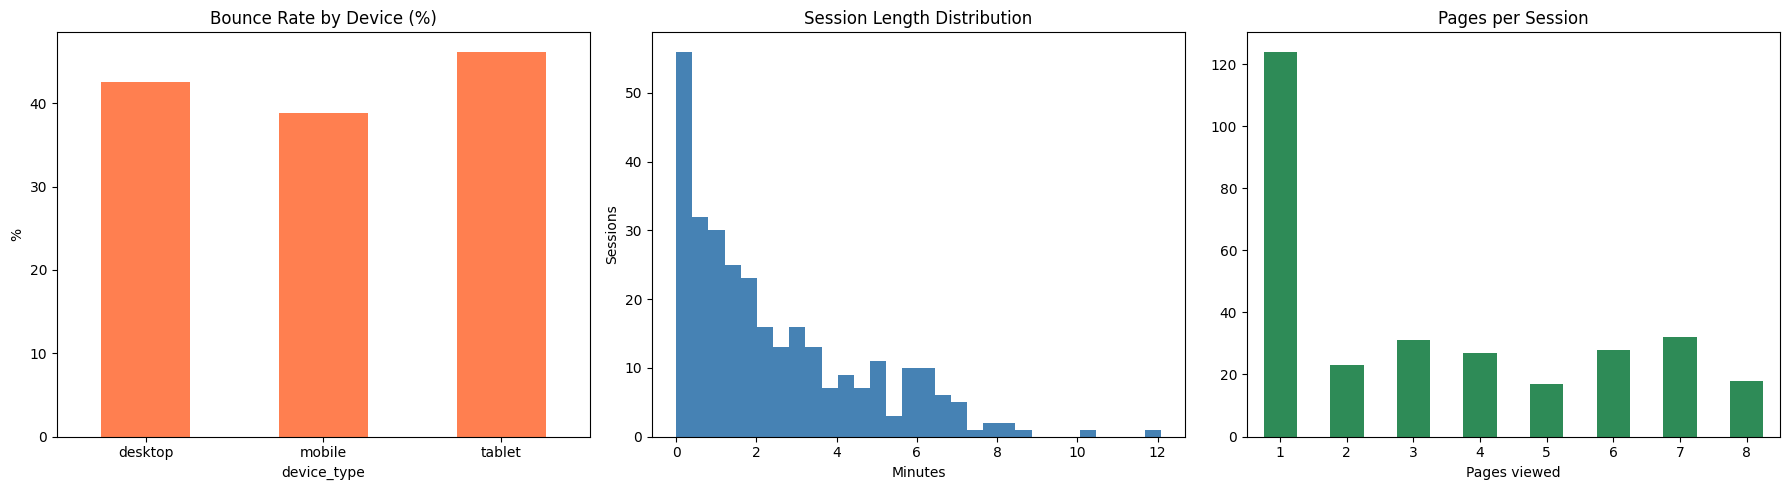

,sessions,bounce_rate,avg_session_minutes,pages_per_session
device_type,,,,
desktop,122,0.426,2.302,3.008
mobile,139,0.388,2.585,3.597
tablet,39,0.462,2.325,3.205


In [7]:
metrics, device_metrics, sessions, report = analyze_user_engagement_v2(logs_df)
plot_engagement(sessions, device_metrics)
device_metrics

In [8]:
comparison = pd.DataFrame({
    'Original (buggy)': [orig_metrics['bounce_rate'], orig_metrics['pages_per_session'].mean(),
                         'Series (not an average)', int((orig_metrics['avg_session_time'] < 0).sum())],
    'Fixed': [round(metrics['bounce_rate'], 3), round(metrics['pages_per_session'], 2),
              round(metrics['avg_session_minutes'], 2), int((sessions['session_seconds'] < 0).sum())],
}, index=['Bounce rate', 'Pages per session', 'Avg session (min)', 'Negative session times'])
comparison

,Original (buggy),Fixed
Bounce rate,1.0,0.413
Pages per session,1.0,3.310
Avg session (min),Series (not an average),2.440
Negative session times,3,0.000


## Comparison summary

| | Vague prompt | Detailed prompt |
|---|---|---|
| Error identification | fixed the session-level aggregation, but didn't explain why | explained each bug's root cause (row grain vs. session grain) |
| Validation | filtered negative rows only; **crashed** on text values | type coercion, duplicate removal, negative values nulled, bot sessions capped, report returned, range assertions |
| Time handling | still summed client durations (dropped negatives) | timestamp-based session length (last − first + last page), sorted events, UTC |
| Visualizations | none | bounce by device, session length histogram, pages-per-session distribution |